# Análisis de sentimiento en reseñas — WeLoveReviews

## 1. Objetivos

El negocio (**Harbor House Café**) tiene una puntuación media de **4.5 / 5**. La account manager quiere saber, antes de presentar el reporte al cliente:

1. ¿Cuántas de las 500 reseñas escritas se leen como **positivas, neutrales o negativas**?
2. ¿Esa distribución **coincide** con el promedio de 4.5 estrellas?
3. Si hay diferencias, **¿de dónde vienen?**

Para responderlo usaremos un modelo preentrenado de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`). Antes de modelar, exploramos los datos.

## 2. Análisis exploratorio (EDA)

### 2.1 Carga y vista general

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

RAW_PATH = "../data/raw/reviews.csv"
df = pd.read_csv(RAW_PATH)
print(df.shape)
df.head()

(500, 3)


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB


El dataset tiene **500 reseñas** y 3 columnas: `review_id`, `rating` (1–5 estrellas, puesto por el cliente) y `review_text` (en inglés).

### 2.2 Calidad de datos

In [3]:
print("Nulos por columna:")
print(df.isna().sum(), "\n")
print("IDs duplicados:", df["review_id"].duplicated().sum())
print("Textos vacíos:", (df["review_text"].str.strip() == "").sum())
print("Espacios sobrantes (inicio/fin/dobles):", df["review_text"].str.contains(r"^\s|\s$|\s{2,}").sum())
print("Ratings fuera de 1–5:", (~df["rating"].between(1, 5)).sum())
print("Textos duplicados (exactos):", df["review_text"].duplicated().sum())

Nulos por columna:
review_id      0
rating         0
review_text    0
dtype: int64 

IDs duplicados: 0
Textos vacíos: 0
Espacios sobrantes (inicio/fin/dobles): 0
Ratings fuera de 1–5: 0
Textos duplicados (exactos): 7


In [4]:
dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
dups[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
50,51,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
112,113,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
176,177,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
291,292,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.
483,484,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.
40,41,5,Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team clearly cares about the customers. Will definitely be back!
107,108,5,Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team clearly cares about the customers. Will definitely be back!
109,110,3,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot."
450,451,3,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot."


Los datos están **muy limpios**: no hay nulos, textos vacíos, IDs repetidos ni ratings inválidos. Solo hay **7 pares de reseñas idénticas** (mismo texto y mismo rating). Son muy pocas (1.4 %) y el cliente entregó 500 reseñas, así que las conservamos y solo las marcamos.

### 2.3 Distribución de las estrellas

,reseñas,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Media de estrellas: 4.50


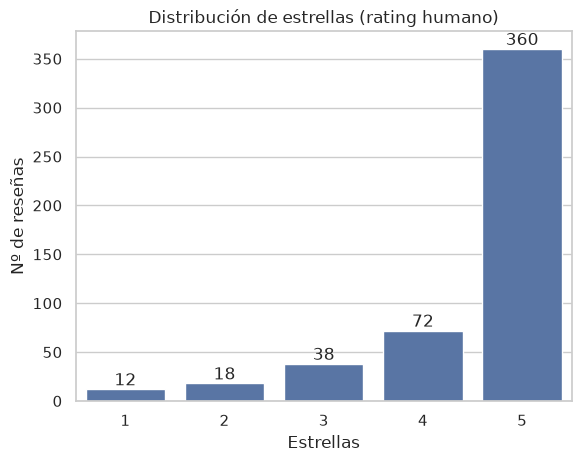

In [5]:
counts = df["rating"].value_counts().sort_index()
pct = (counts / len(df) * 100).round(1)
display(pd.DataFrame({"reseñas": counts, "%": pct}))
print(f"Media de estrellas: {df['rating'].mean():.2f}")

ax = sns.countplot(data=df, x="rating", color="#4C72B0")
ax.bar_label(ax.containers[0])
ax.set(title="Distribución de estrellas (rating humano)", xlabel="Estrellas", ylabel="Nº de reseñas")
plt.show()

In [6]:
def star_band(stars):
    if stars <= 2:
        return "Negativo"
    if stars == 3:
        return "Neutral"
    return "Positivo"

df["rating_band"] = df["rating"].map(star_band)
(df["rating_band"].value_counts(normalize=True) * 100).round(1).reindex(["Positivo", "Neutral", "Negativo"])

rating_band
Positivo    86.4
Neutral      7.6
Negativo     6.0
Name: proportion, dtype: float64

La media de **4.50** confirma la cifra del cliente. Las estrellas están muy concentradas arriba: **72 % son de 5★** y, aplicando el mismo mapeo que usaremos con el modelo, **86.4 % de las reseñas son positivas**, 7.6 % neutrales y 6 % negativas. Esta es la **línea base** contra la que compararemos el sentimiento del texto.

### 2.4 Longitud de las reseñas

,n_words,n_sentences
count,500.0,500.0
mean,29.1,4.2
std,4.8,0.6
min,14.0,3.0
25%,26.0,4.0
50%,29.0,4.0
75%,32.0,5.0
max,42.0,5.0


,n_words,n_sentences
rating,,
1,30.2,4.6
2,26.4,3.9
3,26.8,3.9
4,30.5,3.9
5,29.2,4.3


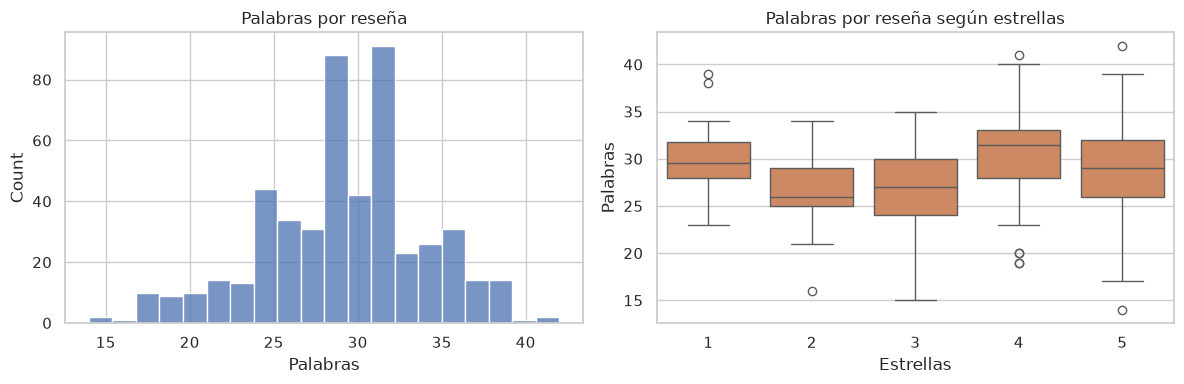

In [7]:
df["n_words"] = df["review_text"].str.split().str.len()
df["n_sentences"] = df["review_text"].str.split(r"(?<=[.!?])\s+").str.len()
display(df[["n_words", "n_sentences"]].describe().round(1))
display(df.groupby("rating")[["n_words", "n_sentences"]].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["n_words"], bins=20, ax=axes[0])
axes[0].set(title="Palabras por reseña", xlabel="Palabras")
sns.boxplot(data=df, x="rating", y="n_words", ax=axes[1], color="#DD8452")
axes[1].set(title="Palabras por reseña según estrellas", xlabel="Estrellas", ylabel="Palabras")
plt.tight_layout()
plt.show()

Son reseñas **cortas**: entre 14 y 42 palabras (unas 29 de media) y de 3 a 5 frases. Quedan muy por debajo del límite de 512 tokens de BERT, así que **no hace falta truncar**. La longitud no cambia mucho según las estrellas.

### 2.5 Estructura del texto: reseñas construidas con frases plantilla

In [8]:
sentences = (
    df.assign(sentence=df["review_text"].str.split(r"(?<=[.!?])\s+"))
      .explode("sentence")
)
print("Frases totales:", len(sentences))
print("Frases únicas:", sentences["sentence"].nunique())
sentences["sentence"].value_counts().head(15)

Frases totales: 2108
Frases únicas: 69


sentence
This is now my go-to spot.                                     92
Will definitely be back!                                       85
Five stars without hesitation.                                 84
Came to Harbor House Café for a birthday brunch.               79
Tried Harbor House Café after seeing it recommended online.    76
Already planning my next visit.                                75
Regular customer at Harbor House Café here.                    74
Grabbed a quick coffee at Harbor House Café this morning.      73
Stopped by Harbor House Café for the first time.               70
Highly recommend to anyone in the area.                        69
The music and decor set the perfect mood.                      68
Worth every penny.                                             65
Visited Harbor House Café last weekend.                        61
Great spot to work or catch up with friends.                   61
The place has such a cozy, welcoming vibe.                     61
N

Solo hay **69 frases distintas** en 500 reseñas: los textos se forman combinando frases de un repertorio fijo (apertura → comida/ambiente → servicio → cierre). Por eso conviene analizar el sentimiento **por frase** y ver en qué estrellas aparece cada una.

In [9]:
sent_by_rating = pd.crosstab(sentences["sentence"], sentences["rating"])
sent_by_rating["total"] = sent_by_rating.sum(axis=1)
sent_by_rating["media_estrellas"] = (
    sentences.groupby("sentence")["rating"].mean().round(2)
)
sent_by_rating.sort_values("media_estrellas")

rating,1,2,3,4,5,total,media_estrellas
sentence,,,,,,,
It was way too loud to hold a conversation.,1,0,0,0,0,1,1.00
Tables were sticky and the floor hadn't been swept.,2,0,0,0,0,2,1.00
The place felt cramped and chaotic.,5,0,0,0,0,5,1.00
The coffee tasted burnt.,6,2,0,0,0,8,1.25
The portions were way too small for the price.,3,2,0,0,0,5,1.40
...,...,...,...,...,...,...,...
"We waited 25 minutes just to get water, but honestly the food made up for it.",0,0,0,0,7,7,5.00
They went out of their way to accommodate my allergy.,0,0,0,0,38,38,5.00
"The place has such a cozy, welcoming vibe.",0,0,0,0,61,61,5.00


La tabla muestra tres tipos de frase:

- **Neutras (aperturas):** "Visited Harbor House Café last weekend.", "Regular customer at…" aparecen con cualquier número de estrellas y no aportan sentimiento.
- **Claramente polarizadas:** "The coffee tasted burnt." solo aparece con 1–2★ y "Worth every penny." solo con 5★.
- **Mixtas (queja + giro positivo):** la queja va seguida de *", but overall a solid experience"* o *", but honestly the food made up for it"*. **Solo aparecen en reseñas de 4–5★.**

### 2.6 Reseñas mixtas: el foco de riesgo para el modelo

In [10]:
MIXED_PATTERNS = {
    "but overall a solid experience": "queja + 'overall a solid experience'",
    "but honestly the food made up for it": "queja + 'the food made up for it'",
}
df["mixed_type"] = "—"
for pattern, label in MIXED_PATTERNS.items():
    df.loc[df["review_text"].str.contains(pattern, regex=False), "mixed_type"] = label
df["is_mixed"] = df["mixed_type"] != "—"

display(pd.crosstab(df["mixed_type"], df["rating"], margins=True, margins_name="Total"))
print(f"Reseñas mixtas: {df['is_mixed'].sum()} ({df['is_mixed'].mean():.1%})")

rating,1,2,3,4,5,Total
mixed_type,,,,,,
queja + 'overall a solid experience',0,0,0,69,0,69
queja + 'the food made up for it',0,0,0,0,21,21
—,12,18,38,3,339,410
Total,12,18,38,72,360,500


Reseñas mixtas: 90 (18.0%)


In [11]:
df.loc[df["is_mixed"], ["review_id", "rating", "review_text"]].sample(5, random_state=42)

,review_id,rating,review_text
249,250,5,"Regular customer at Harbor House Café here. Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Highly recommend to anyone in the ..."
115,116,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Wouldn't go out of my way, but wouldn't ..."
321,322,5,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"
394,395,4,"The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Might give it another shot."
9,10,5,"The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."


**90 reseñas (18 %)** combinan una queja concreta ("We waited 25 minutes just to get water", "The staff seemed annoyed to be there"…) con un balance final positivo:

- **69 de 4★** con *"but overall a solid experience"*: son el 96 % de todas las reseñas de 4★.
- **21 de 5★** con *"but honestly the food made up for it"*.

Una persona las lee como positivas porque el cliente explica que, en conjunto, quedó contento. Un modelo de sentimiento puede dar más peso a la queja explícita y clasificarlas como neutrales o negativas. **Esperamos que la mayoría de los falsos negativos salgan de este grupo.**

### 2.7 Vocabulario de servicio vs. producto

In [12]:
SERVICE_TERMS = r"\b(?:staff|server|service|cashier|team|waited|wait|checked on us|attentive|friendly|rude|annoyed|slow)\b"
AMBIENCE_TERMS = r"\b(?:vibe|music|decor|loud|cramped|chaotic|light|plants|tables|floor|place)\b"
FOOD_TERMS = r"\b(?:coffee|food|dish|pastry|pastries|eggs|sandwiches|bread|menu|brunch|portions|ingredients)\b"

topics = pd.DataFrame({
    "servicio/personal": df["review_text"].str.contains(SERVICE_TERMS, case=False),
    "ambiente/local": df["review_text"].str.contains(AMBIENCE_TERMS, case=False),
    "comida/producto": df["review_text"].str.contains(FOOD_TERMS, case=False),
})
(topics.mean() * 100).round(1).rename("% de reseñas que lo mencionan")

servicio/personal    70.8
ambiente/local       35.6
comida/producto      83.4
Name: % de reseñas que lo mencionan, dtype: float64

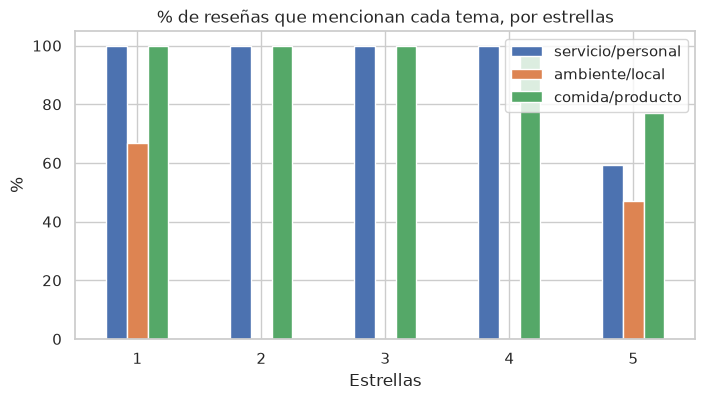

,servicio/personal,ambiente/local,comida/producto
rating,,,
1,100.0,66.7,100.0
2,100.0,0.0,100.0
3,100.0,0.0,100.0
4,100.0,0.0,100.0
5,59.4,47.2,76.9


In [13]:
topic_rating = topics.assign(rating=df["rating"]).groupby("rating").mean().mul(100).round(1)
ax = topic_rating.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set(title="% de reseñas que mencionan cada tema, por estrellas", xlabel="Estrellas", ylabel="%")
plt.show()
topic_rating

El **71 %** de las reseñas hablan del **personal, el servicio o los tiempos de espera**, y en las de **1 a 4★ lo hacen todas (100 %)**. El servicio es justo lo que marca la diferencia entre un 5★ y el resto. Además, un 36 % menciona el **ambiente** del local. El modelo `nlptown` se entrenó con reseñas de **productos**, donde este vocabulario aparece poco. Es el **desajuste de dominio** que avisa el enunciado: frases como "polite but a bit slow" o "waited 25 minutes" pueden pesar más de lo que deberían.

### 2.8 Resumen de insights

| # | Insight | Implicación para el modelado |
|---|---------|------------------------------|
| 1 | Datos limpios: sin nulos, IDs únicos y ratings válidos. Hay 7 pares de textos duplicados. | Limpieza mínima. Conservamos las 500 reseñas y marcamos los duplicados. |
| 2 | Media de 4.50★, con 86.4 % positivas, 7.6 % neutrales y 6 % negativas según las estrellas. | Es la línea base que debe "confirmar" el sentimiento del texto. |
| 3 | Reseñas cortas (14–42 palabras). | No hay riesgo de truncado con BERT (512 tokens). |
| 4 | Solo 69 frases plantilla; muchas aperturas son neutras. | El sentimiento está en las frases de comida, servicio y cierre. |
| 5 | 90 reseñas (18 %) son **mixtas**: una queja seguida de un giro positivo, siempre con 4–5★. | Son las candidatas principales a **falsos negativos**. |
| 6 | El 71 % de las reseñas (y el 100 % de las de 1–4★) hablan del servicio y el personal. | Hay desajuste de dominio con un modelo entrenado en reseñas de productos. |

### 2.9 Propuesta de limpieza

El modelo es **uncased** y trabaja con texto natural, así que **no** aplicamos limpiezas propias de NLP clásico (stopwords, lematización, quitar puntuación). La puntuación y conectores como *"but"* son justo lo que ayuda a entender las reseñas mixtas.

Solo hacemos lo siguiente:
1. Quitar espacios sobrantes (no hay ninguno, pero es una protección barata para futuros lotes).
2. Mantener los acentos ("Café"): el modelo es multilingüe y los admite.
3. Conservar las 500 reseñas, duplicados incluidos, y añadir una marca `is_duplicate`.
4. Guardar las columnas auxiliares (`rating_band`, `is_mixed`, `mixed_type`) para el análisis de resultados.

In [14]:
df["review_text"] = df["review_text"].str.strip().str.replace(r"\s+", " ", regex=True)
df["is_duplicate"] = df["review_text"].duplicated(keep="first")

clean = df[["review_id", "rating", "rating_band", "review_text", "is_mixed", "mixed_type", "is_duplicate"]]
clean.to_csv("../data/interim/reviews_clean.csv", index=False)
print(clean.shape)
clean.head()

(500, 7)


,review_id,rating,rating_band,review_text,is_mixed,mixed_type,is_duplicate
0,1,5,Positivo,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,False,—,False
1,2,5,Positivo,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...,False,—,False
2,3,5,Positivo,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...,False,—,False
3,4,5,Positivo,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,False,—,False
4,5,5,Positivo,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,False,—,False


## 3. Plan de acción y justificación del modelo

### 3.1 ¿Por qué un modelo preentrenado?

No tenemos reseñas etiquetadas por sentimiento ni tiempo para entrenar un modelo, y no es necesario: la pregunta de negocio es **comprobar** si el texto confirma las 4.5★, no construir un clasificador. Un modelo preentrenado de Hugging Face da esa "segunda opinión" independiente de las estrellas.

### 3.2 Modelo elegido: `nlptown/bert-base-multilingual-uncased-sentiment`

| Aspecto | Detalle | Por qué importa aquí |
|---|---|---|
| Salida | 1 a 5 estrellas | Usa **la misma escala que el `rating`**, así que podemos compararlos directamente, reseña por reseña y en media. |
| Arquitectura | BERT base multilingüe, *uncased* | Lee la frase completa con su contexto (conectores como *"but"*). No le afectan mayúsculas ni acentos ("Café"). |
| Idiomas | EN, NL, DE, FR, ES, IT | Nuestras reseñas están en inglés, que está soportado. |
| Entrenamiento | Reseñas de **productos** | ⚠️ **Desajuste de dominio**: nuestras reseñas hablan de un **servicio** (personal, esperas, ambiente). |
| Longitud máxima | 512 tokens | Nuestras reseñas tienen como mucho 42 palabras, así que no se trunca nada. |

### 3.3 Mapeo de estrellas a sentimiento

Aplicamos a las predicciones el **mismo** mapeo que usamos con las estrellas humanas en la EDA (función `star_band`). Así las dos distribuciones se comparan en igualdad de condiciones:

| Predicción del modelo | Banda |
|---|---|
| 1–2 estrellas | Negativo |
| 3 estrellas | Neutral |
| 4–5 estrellas | Positivo |

### 3.4 Reproducibilidad

- **Modelo fijado** por nombre **y** por commit (`revision`). Si el autor sube una versión nueva, nuestro análisis no cambia sin que nos enteremos.
- **Librerías fijadas** en `requirements.txt` (`transformers==5.19.0`, `torch==2.14.1`).
- **Los pesos no se suben al repo**: `pipeline()` los descarga y guarda en la caché local de Hugging Face la primera vez que se ejecuta.
- El modelo se carga **una sola vez** y procesa las 500 reseñas en lotes.

### 3.5 Plan de acción (basado en los insights de la EDA)

| Paso | Qué haremos | Insight de la EDA que lo justifica |
|---|---|---|
| 4 | Inferencia sobre las 500 reseñas, guardando estrellas predichas, confianza y banda. | Los datos están limpios y cortos y no hace falta preprocesarlos más (insights 1 y 3). |
| 5 | Comparar la distribución del modelo con la línea base de **86.4 % / 7.6 % / 6 %** y con la media de 4.5★, más una matriz de confusión. | Las estrellas están muy concentradas en 5★ (insight 2). |
| 6 | Buscar **falsos negativos** (rating 4–5★ y predicción 1–2★) y ver si se concentran en las reseñas mixtas. | El 18 % de las reseñas son mixtas, con una queja y un giro positivo (insight 5). |
| 7 | Analizar qué frases de queja aparecen en los errores. | El 71 % habla del servicio, que no es el dominio del modelo (insight 6). |
| 8 | Revisar a mano 15–20 reseñas (aleatorias y casos dudosos). | No hay etiquetas de sentimiento "verdaderas", así que hace falta criterio humano. |
| 9 | Conclusiones para la account manager. | — |

### 3.6 Hipótesis a validar

- **H1:** El modelo dará **menos del 86.4 % de reseñas positivas**, porque es más severo con las quejas que las propias estrellas.
- **H2:** La mayoría de los **falsos negativos** serán **reseñas mixtas** (`is_mixed = True`), sobre todo las de 4★ con *"but overall a solid experience"*.
- **H3:** Las quejas de **servicio** ("waited 25 minutes", "staff seemed annoyed") pesarán más que el balance final, por el desajuste de dominio.

### 3.7 Configuración

Fijamos los parámetros del modelo y comprobamos, descargando solo su configuración (unos pocos KB, no los pesos), que sus etiquetas son las 5 estrellas que esperamos.

In [15]:
from transformers import AutoConfig

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"  # commit fijado en Hugging Face
BATCH_SIZE = 32

config = AutoConfig.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
print("Arquitectura:", config.architectures)
print("Etiquetas del modelo:", config.id2label)

Arquitectura: ['BertForSequenceClassification']
Etiquetas del modelo: {0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}


El modelo devuelve 5 etiquetas, de `"1 star"` a `"5 stars"`. Para pasarlas a número basta con leer el primer carácter, y después se aplica `star_band` para obtener la banda. Con la configuración validada, pasamos a la inferencia.

## 4. Inferencia sobre las 500 reseñas

### 4.1 Carga del modelo (una sola vez)

Creamos el `pipeline` **una única vez**, fuera de cualquier bucle, con el modelo y el commit fijados en la sección 3.7. La primera ejecución descarga los pesos (~670 MB) a la caché local de Hugging Face; las siguientes los reutilizan.

In [16]:
import time
from transformers import pipeline

t0 = time.perf_counter()
sentiment_clf = pipeline(
    "text-classification",
    model=MODEL_NAME,
    revision=MODEL_REVISION,
    truncation=True,
    device=-1,  # CPU
)
print(f"Modelo cargado en {time.perf_counter() - t0:.1f} s")

Modelo cargado en 2.0 s


### 4.2 Predicción en lote

Pasamos **la lista completa** de textos al pipeline, que los procesa en lotes de `BATCH_SIZE`. Por cada reseña obtenemos la etiqueta más probable (`"4 stars"`) y su probabilidad.

In [17]:
t0 = time.perf_counter()
predictions = sentiment_clf(df["review_text"].tolist(), batch_size=BATCH_SIZE)
elapsed = time.perf_counter() - t0
print(f"{len(predictions)} reseñas procesadas en {elapsed:.1f} s ({elapsed / len(predictions) * 1000:.0f} ms/reseña)")
predictions[:3]

500 reseñas procesadas en 43.2 s (86 ms/reseña)


[{'label': '5 stars', 'score': 0.7169584035873413},
 {'label': '5 stars', 'score': 0.9822202920913696},
 {'label': '5 stars', 'score': 0.6623231768608093}]

### 4.3 Enriquecer el dataset

Convertimos la etiqueta a número (`"4 stars"` → 4), aplicamos el mismo mapeo `star_band` que a las estrellas humanas y añadimos dos columnas de apoyo para el análisis:
- `star_diff`: estrellas predichas − estrellas humanas (negativo ⇒ el modelo es más severo que el cliente).
- `band_match`: si la banda del modelo coincide con la banda de las estrellas.

In [18]:
df["pred_stars"] = [int(p["label"].split()[0]) for p in predictions]
df["pred_score"] = [round(p["score"], 4) for p in predictions]
df["sentiment"] = df["pred_stars"].map(star_band)
df["star_diff"] = df["pred_stars"] - df["rating"]
df["band_match"] = df["sentiment"] == df["rating_band"]

df[["review_id", "rating", "rating_band", "pred_stars", "pred_score", "sentiment", "is_mixed", "review_text"]].head(10)

,review_id,rating,rating_band,pred_stars,pred_score,sentiment,is_mixed,review_text
0,1,5,Positivo,5,0.7170,Positivo,False,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Positivo,5,0.9822,Positivo,False,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,Positivo,5,0.6623,Positivo,False,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,Positivo,5,0.9895,Positivo,False,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Positivo,5,0.9829,Positivo,False,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.
5,6,5,Positivo,5,0.3339,Positivo,False,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. They went out of their way to accommodate my allergy. Will definitely be back!
6,7,5,Positivo,5,0.7980,Positivo,False,Stopped by Harbor House Café for the first time. The team clearly cares about the customers. The sourdough bread alone is worth the visit. Worth every penny. Highly recommend to anyone in the area.
7,8,5,Positivo,5,0.8237,Positivo,False,Came to Harbor House Café for a birthday brunch. Great spot to work or catch up with friends. Our server remembered our names by the second visit. Worth every penny. This is now my go-to spot.
8,9,3,Neutral,3,0.6470,Neutral,False,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop."
9,10,5,Positivo,5,0.5756,Positivo,True,"The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."


### 4.4 Comprobaciones de la inferencia

In [19]:
assert len(df) == 500, "Faltan reseñas"
assert df["pred_stars"].between(1, 5).all(), "Estrellas fuera de rango"
assert df[["pred_stars", "pred_score", "sentiment"]].notna().all().all(), "Predicciones vacías"

print("✔ Las 500 reseñas tienen predicción\n")
print("Estrellas predichas:")
print(df["pred_stars"].value_counts().sort_index().to_string(), "\n")
print("Confianza del modelo (pred_score):")
print(df["pred_score"].describe().round(3).to_string())

✔ Las 500 reseñas tienen predicción

Estrellas predichas:
pred_stars
1     22
2     25
3     41
4     56
5    356 

Confianza del modelo (pred_score):
count    500.000
mean       0.704
std        0.189
min        0.255
25%        0.578
50%        0.703
75%        0.845
max        0.994


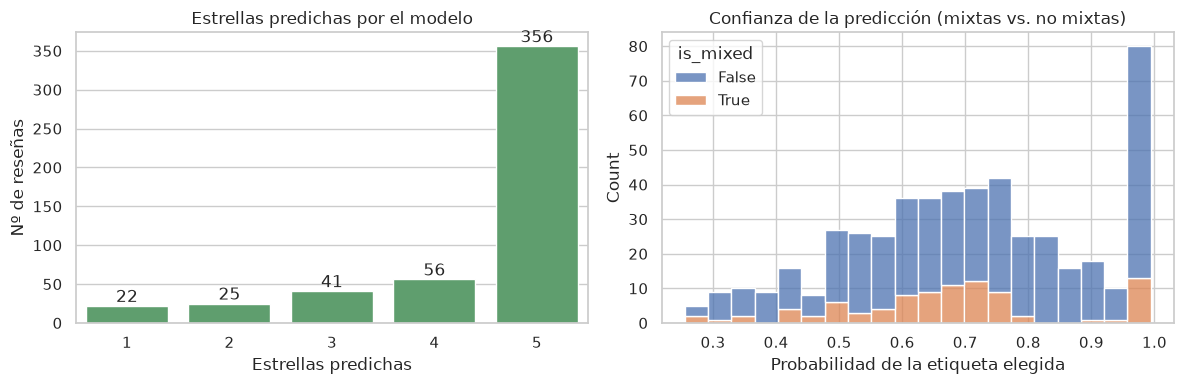

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="pred_stars", order=[1, 2, 3, 4, 5], color="#55A868", ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set(title="Estrellas predichas por el modelo", xlabel="Estrellas predichas", ylabel="Nº de reseñas")
sns.histplot(data=df, x="pred_score", hue="is_mixed", bins=20, multiple="stack", ax=axes[1])
axes[1].set(title="Confianza de la predicción (mixtas vs. no mixtas)", xlabel="Probabilidad de la etiqueta elegida")
plt.tight_layout()
plt.show()

In [21]:
df.groupby("is_mixed")["pred_score"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
is_mixed,,,,,,,,
False,410.0,0.711,0.191,0.268,0.578,0.716,0.855,0.994
True,90.0,0.673,0.177,0.255,0.578,0.671,0.755,0.987


Guardamos las predicciones en `data/interim/` para no tener que repetir la inferencia mientras analizamos. El CSV final de producción (`data/processed/reviews_with_sentiment.csv`) lo generará `src/app.py`.

In [22]:
df.to_csv("../data/interim/reviews_with_predictions.csv", index=False)
print("Guardado:", df.shape)

Guardado: (500, 14)


## 5. Sentimiento del texto vs. promedio de 4.5★

### 5.1 Distribución de sentimiento: estrellas vs. modelo

,Estrellas del cliente (%),Modelo — texto (%),Diferencia (pp)
Positivo,86.4,82.4,-4.0
Neutral,7.6,8.2,0.6
Negativo,6.0,9.4,3.4


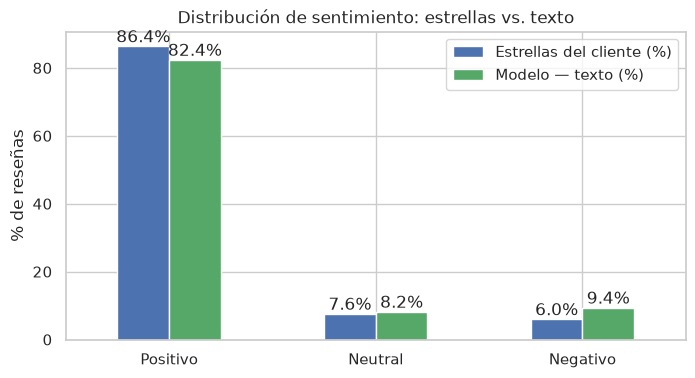

In [23]:
BANDS = ["Positivo", "Neutral", "Negativo"]

dist = pd.DataFrame({
    "Estrellas del cliente (%)": df["rating_band"].value_counts(normalize=True).mul(100),
    "Modelo — texto (%)": df["sentiment"].value_counts(normalize=True).mul(100),
}).reindex(BANDS).round(1)
dist["Diferencia (pp)"] = (dist["Modelo — texto (%)"] - dist["Estrellas del cliente (%)"]).round(1)
display(dist)

ax = dist.iloc[:, :2].plot(kind="bar", rot=0, figsize=(8, 4), color=["#4C72B0", "#55A868"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
ax.set(title="Distribución de sentimiento: estrellas vs. texto", xlabel="", ylabel="% de reseñas")
plt.show()

Según el modelo, **el 82.4 % de las reseñas se leen como positivas**, frente al 86.4 % de las estrellas. Hay 4 puntos menos de positivas y casi todos pasan a **negativas** (+3.4 pp). La forma de la distribución es la misma: una gran mayoría positiva con pocas neutrales y negativas.

### 5.2 Media de estrellas: 4.40 vs. 4.50

In [24]:
means = pd.DataFrame({
    "Media de estrellas": [df["rating"].mean(), df["pred_stars"].mean()],
}, index=["Estrellas del cliente", "Modelo (texto)"]).round(2)
display(means)

per_rating = df.groupby("rating").agg(
    reseñas=("pred_stars", "size"),
    media_predicha=("pred_stars", "mean"),
    pct_misma_banda=("band_match", lambda s: s.mean() * 100),
).round({"media_predicha": 2, "pct_misma_banda": 1})
per_rating

,Media de estrellas
Estrellas del cliente,4.5
Modelo (texto),4.4


,reseñas,media_predicha,pct_misma_banda
rating,,,
1,12,1.75,100.0
2,18,1.72,88.9
3,38,2.92,92.1
4,72,4.21,94.4
5,360,4.81,95.6


La media predicha es **4.40★**, una décima por debajo de la puntuación del negocio. Por nivel de estrellas, el modelo **se acerca mucho al cliente**: las reseñas de 1–2★ reciben de media ~1.7★, las de 3★ 2.9★ y las de 5★ 4.8★.

### 5.3 Matriz de confusión: estrellas del cliente vs. estrellas predichas

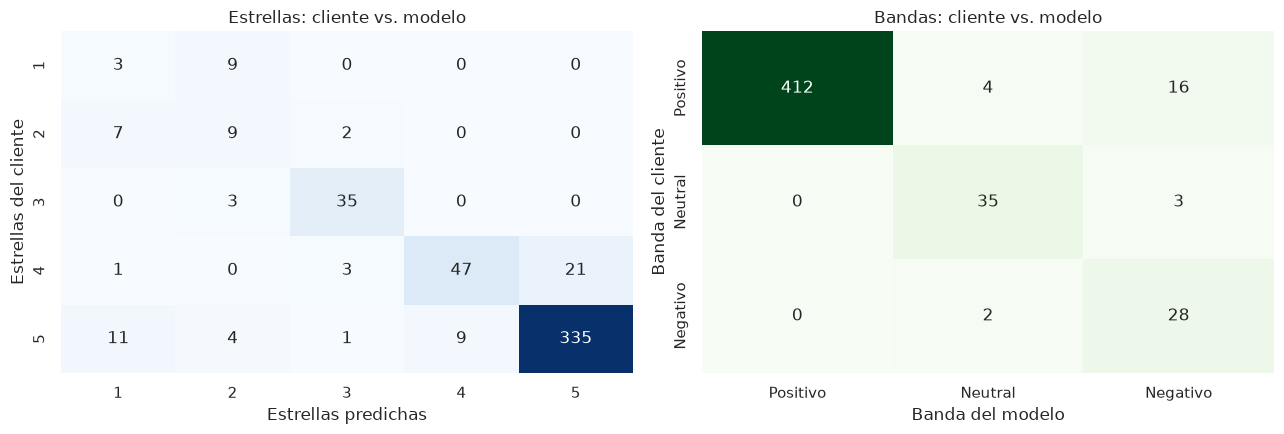

Coincidencia exacta de estrellas: 85.8%
Coincidencia a ±1 estrella:       96.6%
Coincidencia de banda:            95.0%


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

stars_cm = pd.crosstab(df["rating"], df["pred_stars"]).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
sns.heatmap(stars_cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Estrellas: cliente vs. modelo", xlabel="Estrellas predichas", ylabel="Estrellas del cliente")

bands_cm = pd.crosstab(df["rating_band"], df["sentiment"]).reindex(index=BANDS, columns=BANDS, fill_value=0)
sns.heatmap(bands_cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set(title="Bandas: cliente vs. modelo", xlabel="Banda del modelo", ylabel="Banda del cliente")

plt.tight_layout()
plt.show()

print(f"Coincidencia exacta de estrellas: {(df['star_diff'] == 0).mean():.1%}")
print(f"Coincidencia a ±1 estrella:       {(df['star_diff'].abs() <= 1).mean():.1%}")
print(f"Coincidencia de banda:            {df['band_match'].mean():.1%}")

El modelo **coincide con el cliente en la banda de sentimiento en el 95 % de las reseñas** (475 de 500) y en la estrella exacta en el 85.8 %. Fuera de la diagonal hay dos tipos de diferencia:

- **Pequeñas (±1 estrella), casi todas dentro de la misma banda:** por ejemplo 21 reseñas de 4★ que el modelo sube a 5★, o 9 de 5★ que baja a 4★. No afectan a la distribución de sentimiento.
- **Grandes y aisladas:** **11 reseñas de 5★ que el modelo puntúa con 1★** y otras 4 que puntúa con 2★. Una persona nunca confundiría un 5★ con un 1★, así que estas son las diferencias que hay que explicar.

### 5.4 ¿De dónde viene la diferencia?

In [26]:
mismatches = df[~df["band_match"]]
transitions = pd.crosstab(
    mismatches["rating_band"] + " → " + mismatches["sentiment"],
    mismatches["is_mixed"].map({True: "mixta", False: "no mixta"}),
    margins=True, margins_name="Total",
)
display(transitions)

df["false_negative"] = (df["rating"] >= 4) & (df["pred_stars"] <= 2)
print(f"Falsos negativos (rating 4–5★ y modelo 1–2★): {df['false_negative'].sum()}")
print(f"  de ellos, reseñas mixtas: {df.loc[df['false_negative'], 'is_mixed'].sum()}")

is_mixed,mixta,no mixta,Total
row_0,,,
Negativo → Neutral,0,2,2
Neutral → Negativo,0,3,3
Positivo → Negativo,2,14,16
Positivo → Neutral,4,0,4
Total,6,19,25


Falsos negativos (rating 4–5★ y modelo 1–2★): 16
  de ellos, reseñas mixtas: 2


In [27]:
without_fn = df[~df["false_negative"]]
impact = pd.DataFrame({
    "reseñas": [len(df), len(without_fn)],
    "media cliente": [df["rating"].mean(), without_fn["rating"].mean()],
    "media modelo": [df["pred_stars"].mean(), without_fn["pred_stars"].mean()],
    "% positivo cliente": [(df["rating_band"] == "Positivo").mean() * 100, (without_fn["rating_band"] == "Positivo").mean() * 100],
    "% positivo modelo": [(df["sentiment"] == "Positivo").mean() * 100, (without_fn["sentiment"] == "Positivo").mean() * 100],
}, index=["Todas las reseñas", "Sin los 16 falsos negativos"]).round(2)
impact

,reseñas,media cliente,media modelo,% positivo cliente,% positivo modelo
Todas las reseñas,500,4.50,4.4,86.40,82.40
Sin los 16 falsos negativos,484,4.49,4.5,85.95,85.12


,count,mean,std,min,25%,50%,75%,max
band_match,,,,,,,,
no coincide,25.0,0.410,0.123,0.255,0.325,0.389,0.472,0.751
coincide banda,475.0,0.719,0.179,0.271,0.591,0.714,0.854,0.994


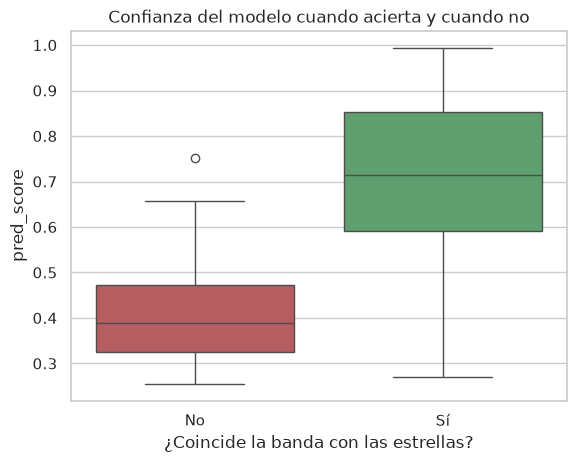

In [28]:
display(df.groupby("band_match")["pred_score"].describe().round(3).rename(index={True: "coincide banda", False: "no coincide"}))

ax = sns.boxplot(data=df, x="band_match", y="pred_score", hue="band_match", palette=["#C44E52", "#55A868"], legend=False)
ax.set(title="Confianza del modelo cuando acierta y cuando no", xlabel="¿Coincide la banda con las estrellas?", ylabel="pred_score")
ax.set_xticks([0, 1], ["No", "Sí"])
plt.show()

**Toda la diferencia se explica por un grupo pequeño y concreto de reseñas:**

1. **16 falsos negativos.** Son reseñas de 4–5★ que el modelo clasifica como negativas, y explican **todo** el hueco: si se excluyen, la media del modelo sube a **4.50★**, igual que la del cliente (4.49★), y el porcentaje de positivas casi coincide (85.1 % frente a 86.0 %).
2. **Son predicciones de baja confianza.** Cuando el modelo no coincide con las estrellas, su confianza media es **0.41**, frente a **0.72** cuando sí coincide. En los falsos negativos la probabilidad típica de la etiqueta elegida está entre 0.27 y 0.48, apenas por encima del azar entre 5 clases (0.20). El modelo **duda** y elige "1 star" por un margen pequeño.
3. **No vienen de las reseñas mixtas.** Solo 2 de los 16 son mixtas (otras 4 mixtas pasan de positivo a neutral, un error menor). Las reseñas del tipo *"queja, but overall a solid experience"* se clasifican como positivas en el 96 % de los casos.

### 5.5 Estado de las hipótesis

| Hipótesis | Resultado |
|---|---|
| **H1:** el modelo dará menos del 86.4 % de positivas | ✅ **Se confirma**, pero la diferencia es pequeña: 82.4 % (−4 pp). |
| **H2:** los falsos negativos serán sobre todo reseñas mixtas | ❌ **Se descarta**: solo 2 de 16. El modelo sí entiende el giro *"but overall…"*. |
| **H3:** las quejas de servicio pesarán más que el balance final | ⚠️ **Por revisar**: casi todos los falsos negativos **no contienen ninguna queja**. La causa parece otra y la analizamos en la sección 6. |

**Respuesta para la account manager:** *sí, el texto de las reseñas respalda las 4.5★*. Las bandas coinciden en el 95 % de los casos y la pequeña diferencia que queda viene de unas 16 reseñas claramente positivas que el modelo clasifica mal. **Es un error del modelo, no un problema oculto del negocio.**

## 6. Falsos negativos

Definimos **falso negativo** como una reseña con **4–5★ del cliente** que el modelo puntúa con **1–2★** (banda negativa).

### 6.1 Los 16 casos

In [29]:
fn_df = df[df["false_negative"]]
fn_df[["review_id", "rating", "pred_stars", "pred_score", "is_mixed", "review_text"]]

,review_id,rating,pred_stars,pred_score,is_mixed,review_text
13,14,4,1,0.4443,False,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,False,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,False,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,False,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,False,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,False,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,True,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my ne..."
253,254,5,1,0.3641,False,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,False,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,True,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Al leerlos, **todos son reseñas claramente positivas**: elogian la comida, el ambiente y el personal y cierran con intención de volver. Solo 2 incluyen una queja, que además se compensa enseguida (*"but honestly the food made up for it"*). Ninguna persona las leería como negativas.

### 6.2 ¿Qué frases comparten?

In [30]:
sentences = sentences.merge(df[["review_id", "false_negative"]], on="review_id")
pos_sentences = sentences[sentences["rating"] >= 4]

phrase_fn = pos_sentences.groupby("sentence").agg(
    apariciones=("false_negative", "size"),
    en_falsos_negativos=("false_negative", "sum"),
)
phrase_fn["% de los 16 FN que la contienen"] = (phrase_fn["en_falsos_negativos"] / df["false_negative"].sum() * 100).round(1)
phrase_fn["tasa de FN cuando aparece (%)"] = (phrase_fn["en_falsos_negativos"] / phrase_fn["apariciones"] * 100).round(1)
phrase_fn.query("en_falsos_negativos > 0").sort_values("en_falsos_negativos", ascending=False).head(8)

,apariciones,en_falsos_negativos,% de los 16 FN que la contienen,tasa de FN cuando aparece (%)
sentence,,,,
Every dish was bursting with flavor.,41,12,75.0,29.3
Already planning my next visit.,75,11,68.8,14.7
Tried Harbor House Café after seeing it recommended online.,68,6,37.5,8.8
Stopped by Harbor House Café for the first time.,61,6,37.5,9.8
Will definitely be back!,85,4,25.0,4.7
They went out of their way to accommodate my allergy.,38,4,25.0,10.5
The team clearly cares about the customers.,49,3,18.8,6.1
Service was fast and friendly.,56,3,18.8,5.4


Destacan dos frases de contenido, más una de cierre:
- **"Every dish was bursting with flavor."** aparece en **12 de los 16** falsos negativos.
- **"They went out of their way to accommodate my allergy."** aparece en los **otros 4**.
- **"Already planning my next visit."** es el cierre de 11 de los 16.

Las aperturas ("Tried…", "Stopped by…") también salen en la lista, pero solo porque aparecen en casi todas las reseñas.

### 6.3 Palabras desencadenantes: *"bursting"* y *"allergy"*

In [31]:
df["trigger_word"] = df["review_text"].str.contains(r"\bbursting\b|\ballergy\b", case=False)

display(pd.crosstab(
    df["trigger_word"].map({True: "contiene bursting/allergy", False: "no contiene"}),
    df["false_negative"].map({True: "falso negativo", False: "resto"}),
    margins=True, margins_name="Total",
))

false_negative,falso negativo,resto,Total
trigger_word,,,
contiene bursting/allergy,16,63,79
no contiene,0,421,421
Total,16,484,500


In [32]:
df["closing"] = df["review_text"].str.split(r"(?<=[.!?])\s+").str[-1]
triggered = df[df["trigger_word"] & (df["rating"] >= 4)]
closing_effect = triggered.groupby("closing").agg(
    reseñas=("false_negative", "size"),
    falsos_negativos=("false_negative", "sum"),
)
closing_effect["tasa FN (%)"] = (closing_effect["falsos_negativos"] / closing_effect["reseñas"] * 100).round(1)
closing_effect.sort_values("tasa FN (%)", ascending=False)

,reseñas,falsos_negativos,tasa FN (%)
closing,,,
Already planning my next visit.,15,11,73.3
Will definitely be back!,16,4,25.0
This is now my go-to spot.,17,1,5.9
Five stars without hesitation.,22,0,0.0
It's fine for a quick stop.,1,0,0.0
Highly recommend to anyone in the area.,8,0,0.0


Dos hallazgos clave:

1. **El 100 % de los falsos negativos contiene "bursting" o "allergy"**, y **ninguna** de las 421 reseñas sin esas palabras es un falso negativo.
2. Esas palabras **no siempre** hacen fallar al modelo: lo que importa es **qué frase de cierre las acompaña**.
   - Con **"Already planning my next visit."**, un cierre positivo pero sin palabras de valoración, el modelo falla en el **73 %** de los casos.
   - Con **"Five stars without hesitation."** o **"Highly recommend…"**, que llevan vocabulario de valoración explícito, falla en el **0 %**.

### 6.4 Experimento: probar frases sueltas en el modelo

Para confirmar la causa, pasamos al modelo las frases sospechosas **solas**, frente a una versión parafraseada con el mismo significado. También añadimos dos frases típicas de **reseñas de productos** con las mismas palabras.

In [33]:
probe_texts = [
    "Every dish was bursting with flavor.",
    "Every dish was full of flavor.",
    "They went out of their way to accommodate my allergy.",
    "They went out of their way to accommodate my dietary needs.",
    "Already planning my next visit.",
    "Five stars without hesitation.",
    "The bag was bursting at the seams.",   # contexto típico de reseña de producto
    "This cream gave me an allergy.",       # contexto típico de reseña de producto
]
probe = sentiment_clf(probe_texts, top_k=None)
probe_df = pd.DataFrame(
    [{p["label"]: round(p["score"], 2) for p in scores} for scores in probe],
    index=probe_texts,
)[["1 star", "2 stars", "3 stars", "4 stars", "5 stars"]]
probe_df["predicción"] = probe_df.idxmax(axis=1)
probe_df

,1 star,2 stars,3 stars,4 stars,5 stars,predicción
Every dish was bursting with flavor.,0.67,0.27,0.05,0.01,0.00,1 star
Every dish was full of flavor.,0.04,0.03,0.06,0.26,0.61,5 stars
They went out of their way to accommodate my allergy.,0.44,0.34,0.14,0.05,0.04,1 star
They went out of their way to accommodate my dietary needs.,0.18,0.22,0.19,0.20,0.21,2 stars
Already planning my next visit.,0.06,0.08,0.17,0.33,0.36,5 stars
Five stars without hesitation.,0.00,0.00,0.00,0.00,0.99,5 stars
The bag was bursting at the seams.,0.45,0.42,0.12,0.01,0.00,1 star
This cream gave me an allergy.,0.52,0.28,0.11,0.05,0.04,1 star


- *"Every dish was **bursting** with flavor."* → **1★ (67 %)**. La misma idea con *"full of flavor"* → **5★ (61 %)**.
- *"…accommodate my **allergy**."* → **1★ (44 %)**. Con *"dietary needs"*, la probabilidad queda repartida entre todas las clases.
- *"The bag was **bursting** at the seams."* y *"This cream gave me an **allergy**."* también salen **1★**: en reseñas de productos, esas palabras describen **defectos** (un envase que revienta, una reacción alérgica).

### 6.5 Contrafactual: ¿se corrigen los 16 casos cambiando solo esas palabras?

In [34]:
counterfactual = fn_df["review_text"] \
    .str.replace("bursting with flavor", "full of flavor", regex=False) \
    .str.replace("accommodate my allergy", "accommodate my dietary needs", regex=False)

cf_preds = sentiment_clf(counterfactual.tolist(), batch_size=BATCH_SIZE)
cf_result = pd.DataFrame({
    "review_id": fn_df["review_id"].values,
    "rating": fn_df["rating"].values,
    "pred_original": fn_df["pred_stars"].values,
    "pred_contrafactual": [int(p["label"].split()[0]) for p in cf_preds],
})
display(cf_result)
print(f"Falsos negativos corregidos: {(cf_result['pred_contrafactual'] >= 4).sum()} / {len(cf_result)}")

,review_id,rating,pred_original,pred_contrafactual
0,14,4,1,5
1,15,5,1,5
2,73,5,1,5
3,87,5,1,5
4,138,5,2,4
5,200,5,2,5
6,204,5,1,4
7,254,5,1,5
8,270,5,1,5
9,322,5,1,5


Falsos negativos corregidos: 16 / 16


**Los 16 falsos negativos pasan a 4–5★** solo con cambiar esas dos expresiones por sinónimos. La causa queda confirmada.

### 6.6 Hipótesis: por qué falla un modelo de productos con reseñas de servicio

`nlptown` se entrenó con **reseñas de productos**. En ese dominio:
- **"bursting"** suele ir con *bursting at the seams*, *the bag burst* o *the package was bursting open*, es decir, con **productos rotos o defectuosos**.
- **"allergy"** suele ir con *gave me an allergy* o *I had an allergic reaction*, es decir, con un **producto que causó un daño**.

El modelo aprendió que estas palabras **anticipan una estrella**. En una reseña de **servicio** significan lo contrario: *bursting with flavor* es un gran elogio, y *accommodate my allergy* destaca un **personal atento**. Esto es el **desajuste de dominio**: el modelo reconoce las palabras pero las interpreta con el contexto de otro dominio.

Además, el error **solo se impone cuando el resto de la reseña no tiene vocabulario de valoración fuerte**. *"Five stars…"* o *"Highly recommend…"* son frases muy frecuentes en reseñas de productos y el modelo las pesa mucho. *"Already planning my next visit"* es positivo, pero es lenguaje de **servicio** y le pesa menos.

Esto también explica el resultado de **H3**: las quejas de servicio no son el problema. El modelo lee bien *"we waited 25 minutes, but overall a solid experience"*. El problema son **los elogios formulados con vocabulario que en productos significa defecto**.

### 6.7 Señal de alerta: la confianza

In [35]:
print(f"Reseñas con pred_score < 0.5: {(df['pred_score'] < 0.5).sum()}")
print(f"Falsos negativos con pred_score < 0.5: {(fn_df['pred_score'] < 0.5).sum()} / {len(fn_df)}")

Reseñas con pred_score < 0.5: 73
Falsos negativos con pred_score < 0.5: 15 / 16


15 de los 16 falsos negativos tienen una confianza **menor de 0.5**. Marcar para revisión humana las predicciones por debajo de ese umbral (73 reseñas, un 15 % del total) detectaría casi todos los errores. Esta regla está implementada en `src/app.py` como columna `needs_review`.

## 7. Revisión manual (20 reseñas)

Elegimos una muestra **reproducible** que combina:
- **10 aleatorias**, para estimar el acierto en general;
- **4 falsos negativos**;
- **3 reseñas mixtas**;
- **3 con la confianza más baja**, que no son falsos negativos.

Cada reseña se leyó a mano y se anotó si la banda del modelo es la que asignaría una persona.

In [36]:
rand = df.sample(10, random_state=42)
fn_s = df[df["false_negative"] & ~df["review_id"].isin(rand["review_id"])].sample(4, random_state=42)
used = pd.concat([rand, fn_s])["review_id"]
mixed_s = df[df["is_mixed"] & ~df["review_id"].isin(used)].sample(3, random_state=42)
used = pd.concat([used, mixed_s["review_id"]])
low_s = df[~df["false_negative"] & ~df["review_id"].isin(used)].nsmallest(3, "pred_score")

manual = pd.concat([
    rand.assign(origen="aleatoria"),
    fn_s.assign(origen="falso negativo"),
    mixed_s.assign(origen="mixta"),
    low_s.assign(origen="baja confianza"),
])

# Notas escritas tras leer cada reseña: (¿la banda del modelo es correcta?, comentario)
MANUAL_NOTES = {
    362: (True,  "Texto tibio ('okay', 'average', 'fine'): 3★ neutral, igual que el cliente."),
    74:  (True,  "Contiene 'bursting', pero el cierre 'Five stars without hesitation' lo compensa."),
    375: (True,  "Todo positivo. Confianza baja (0.49) porque duda entre 4 y 5★, no entre bandas."),
    156: (True,  "Mixta (personal antipático + 'solid experience'): 4★ exacto, buena lectura del matiz."),
    105: (True,  "Elogios a personal, ambiente y precio: 5★ con alta confianza."),
    395: (True,  "Mixta (espera de 25 min + 'solid experience'): 4★ exacto."),
    378: (True,  "Claramente positiva: 5★."),
    125: (True,  "Claramente positiva: 5★."),
    69:  (True,  "Claramente positiva: 5★."),
    451: (True,  "'Average', 'polite but slow', 'might give it another shot': neutral correcto."),
    14:  (False, "Todo elogios. 'bursting' + cierre 'Already planning…' → 1★. Debería ser 4–5★."),
    15:  (False, "Tres frases positivas y ninguna queja. Mismo patrón 'bursting' → 1★."),
    200: (False, "Ambiente + comida + volver. 'bursting' arrastra la predicción a 2★."),
    474: (False, "Incluso con 'go-to spot', 'bursting' pesa más → 1★. Error claro."),
    412: (True,  "Mixta: café excelente, espera larga, 'solid experience' → 4★, correcto."),
    10:  (True,  "Mixta con 'the food made up for it' → 5★, coincide con el cliente."),
    133: (True,  "Mixta suave ('average service, no complaints') → 4★, correcto."),
    253: (False, "Dice 'go-to spot': es positiva. 'bursting' + matiz de servicio → 3★ con 0.26 de confianza."),
    477: (False, "Queja compensada + 'planning my next visit' → 3★. Una persona la lee positiva (5★)."),
    315: (True,  "Correcta (5★), aunque la confianza es baja (0.27): reparte probabilidad entre 4 y 5★."),
}
assert set(MANUAL_NOTES) == set(manual["review_id"]), "La muestra no coincide con las notas"

manual["banda_correcta"] = manual["review_id"].map(lambda i: MANUAL_NOTES[i][0])
manual["nota"] = manual["review_id"].map(lambda i: MANUAL_NOTES[i][1])
manual[["review_id", "origen", "rating", "pred_stars", "pred_score", "sentiment", "banda_correcta", "nota", "review_text"]]

,review_id,origen,rating,pred_stars,pred_score,sentiment,banda_correcta,nota,review_text
361,362,aleatoria,3,3,0.7697,Neutral,True,"Texto tibio ('okay', 'average', 'fine'): 3★ neutral, igual que el cliente.","Stopped by Harbor House Café for the first time. The coffee was okay. Average service, no complaints. It's fine for a quick stop."
73,74,aleatoria,5,5,0.9362,Positivo,True,"Contiene 'bursting', pero el cierre 'Five stars without hesitation' lo compensa.","Stopped by Harbor House Café for the first time. The place has such a cozy, welcoming vibe. Every dish was bursting with flavor. Five stars without hesitation."
374,375,aleatoria,5,5,0.4889,Positivo,True,"Todo positivo. Confianza baja (0.49) porque duda entre 4 y 5★, no entre bandas.","Grabbed a quick coffee at Harbor House Café this morning. Service was fast and friendly. The place has such a cozy, welcoming vibe. Reasonably priced for the quality. Already planning my next visit."
155,156,aleatoria,4,4,0.7073,Positivo,True,"Mixta (personal antipático + 'solid experience'): 4★ exacto, buena lectura del matiz.","Grabbed a quick coffee at Harbor House Café this morning. The coffee was rich and perfectly brewed. The staff seemed annoyed to be there, but overall a solid experience. It's fine for a quick stop."
104,105,aleatoria,5,5,0.8384,Positivo,True,"Elogios a personal, ambiente y precio: 5★ con alta confianza.",Grabbed a quick coffee at Harbor House Café this morning. The staff were warm and attentive. The music and decor set the perfect mood. Great value for what you get. This is now my go-to spot.
394,395,aleatoria,4,4,0.7036,Positivo,True,Mixta (espera de 25 min + 'solid experience'): 4★ exacto.,"The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Might give it another shot."
377,378,aleatoria,5,5,0.7501,Positivo,True,Claramente positiva: 5★.,Visited Harbor House Café last weekend. Loved the natural light and the plants everywhere. The sourdough bread alone is worth the visit. Worth every penny. This is now my go-to spot.
124,125,aleatoria,5,5,0.7512,Positivo,True,Claramente positiva: 5★.,Regular customer at Harbor House Café here. The team clearly cares about the customers. Great spot to work or catch up with friends. Worth every penny. Highly recommend to anyone in the area.
68,69,aleatoria,5,5,0.8210,Positivo,True,Claramente positiva: 5★.,"Visited Harbor House Café last weekend. The place has such a cozy, welcoming vibe. The food was absolutely delicious. Worth every penny. Will definitely be back!"
450,451,aleatoria,3,3,0.6530,Neutral,True,"'Average', 'polite but slow', 'might give it another shot': neutral correcto.","Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot."


In [37]:
manual.groupby("origen", sort=False)["banda_correcta"].agg(revisadas="size", correctas="sum")

,revisadas,correctas
origen,,
aleatoria,10,10
falso negativo,4,0
mixta,3,3
baja confianza,3,1


**Resultado de la revisión manual:**
- **Aleatorias: 10 de 10 correctas.** Encaja con el 95 % de coincidencia de banda que vimos en la sección 5.
- **Mixtas: 3 de 3 correctas.** El modelo entiende bien *"queja, but overall…"*.
- **Falsos negativos: 4 de 4 incorrectos**, todos con el patrón *"bursting"* descrito en la sección 6.
- **Baja confianza: 1 de 3 correcta.** Las dos incorrectas no son falsos negativos "oficiales" (el modelo les da 3★, no 1–2★), pero a una persona le parecen positivas, y una de ellas también contiene *"bursting"*. Confirma que **una confianza baja es una buena señal para revisar a mano**.

En total, **14 de 20 correctas (70 %)**. Esta cifra es baja a propósito, porque la muestra se sobrecargó con casos difíciles. En la parte aleatoria, que es la representativa, el acierto es del 100 %.

## 8. Conclusiones

### Respuesta para la account manager

> **Sí: lo que escriben los clientes respalda la puntuación de 4.5★.**
>
> - Según el texto, **8 de cada 10 reseñas (82 %) son positivas**, un 8 % neutrales y un 9 % negativas. Las estrellas dan 86 % / 8 % / 6 %.
> - En **95 de cada 100** reseñas, el texto y las estrellas dicen lo mismo.
> - La pequeña diferencia **no es un problema oculto del negocio**. Viene de **16 reseñas muy positivas** que el modelo leyó mal porque usan expresiones como *"bursting with flavor"* o *"accommodated my allergy"*. Sin esas 16, el texto da **exactamente 4.5★**.
> - Lo que sí se lee en las reseñas: **la comida y el ambiente reciben elogios constantes**. Cuando hay quejas, son casi siempre **de servicio** (esperas, pedidos equivocados, personal antipático). Incluso los clientes de 4★ mencionan alguna, aunque terminan satisfechos. **Mejorar el servicio es la palanca para convertir esos 4★ en 5★.**

### Conclusiones técnicas

1. **El modelo sirve para esta tarea**: hay un 95 % de coincidencia de banda y una media de 4.40★ frente a 4.50★.
2. **Sus errores son sistemáticos, no aleatorios.** Todos los falsos negativos se explican por **desajuste de dominio**: palabras que en reseñas de productos indican defecto ("bursting", "allergy") y que en reseñas de servicio son elogios. Un contrafactual con sinónimos corrige los 16 casos.
3. **El modelo sí entiende los matices**: el 93 % de las reseñas mixtas (queja + balance positivo) se clasifica como positiva.
4. **La confianza es una buena alarma**: el 94 % de los falsos negativos tiene `pred_score < 0.5`. En producción, esas reseñas se marcan con `needs_review`.

### Limitaciones

- El dataset se construye con solo 69 frases plantilla. En reseñas reales habrá más variedad y posiblemente otros desencadenantes del mismo tipo.
- No hay etiquetas de sentimiento verdaderas. Usamos las estrellas del cliente como referencia y una revisión manual de 20 reseñas.

### Producción

La lógica de inferencia está en **`src/app.py`**. Carga el modelo fijado una sola vez, procesa todas las reseñas en lotes y escribe **`data/processed/reviews_with_sentiment.csv`**, con las estrellas predichas, la banda, la confianza y las marcas `false_negative` y `needs_review`.

## 9. Addendum (extensión opcional): ¿un modelo mejor?

Probamos [`tabularisai/multilingual-sentiment-analysis`](https://huggingface.co/tabularisai/multilingual-sentiment-analysis), un DistilBERT multilingüe con 5 clases (*Very Negative* … *Very Positive*). Lo fijamos también a un commit y mapeamos sus clases a 1–5 estrellas para compararlo en igualdad de condiciones.

In [38]:
ALT_MODEL_NAME = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"
ALT_LABEL_TO_STARS = {"Very Negative": 1, "Negative": 2, "Neutral": 3, "Positive": 4, "Very Positive": 5}

alt_clf = pipeline("text-classification", model=ALT_MODEL_NAME, revision=ALT_MODEL_REVISION, truncation=True, device=-1)
alt_preds = alt_clf(df["review_text"].tolist(), batch_size=BATCH_SIZE)

df["alt_stars"] = [ALT_LABEL_TO_STARS[p["label"]] for p in alt_preds]
df["alt_score"] = [round(p["score"], 4) for p in alt_preds]
df["alt_sentiment"] = df["alt_stars"].map(star_band)
df["alt_false_negative"] = (df["rating"] >= 4) & (df["alt_stars"] <= 2)

In [39]:
def model_metrics(stars, band):
    return {
        "% positivo": (band == "Positivo").mean() * 100,
        "% neutral": (band == "Neutral").mean() * 100,
        "% negativo": (band == "Negativo").mean() * 100,
        "media estrellas": stars.mean(),
        "coincidencia banda (%)": (band == df["rating_band"]).mean() * 100,
        "coincidencia estrella exacta (%)": (stars == df["rating"]).mean() * 100,
        "neutrales bien detectadas": ((df["rating_band"] == "Neutral") & (band == "Neutral")).sum(),
        "falsos negativos": ((df["rating"] >= 4) & (stars <= 2)).sum(),
    }

comparison = pd.DataFrame({
    "Estrellas cliente": model_metrics(df["rating"], df["rating_band"]),
    "nlptown": model_metrics(df["pred_stars"], df["sentiment"]),
    "tabularisai": model_metrics(df["alt_stars"], df["alt_sentiment"]),
}).round(1)
comparison

,Estrellas cliente,nlptown,tabularisai
% positivo,86.4,82.4,88.8
% neutral,7.6,8.2,2.2
% negativo,6.0,9.4,9.0
media estrellas,4.5,4.4,3.8
coincidencia banda (%),100.0,95.0,90.6
coincidencia estrella exacta (%),100.0,85.8,22.2
neutrales bien detectadas,38.0,35.0,5.0
falsos negativos,0.0,16.0,7.0


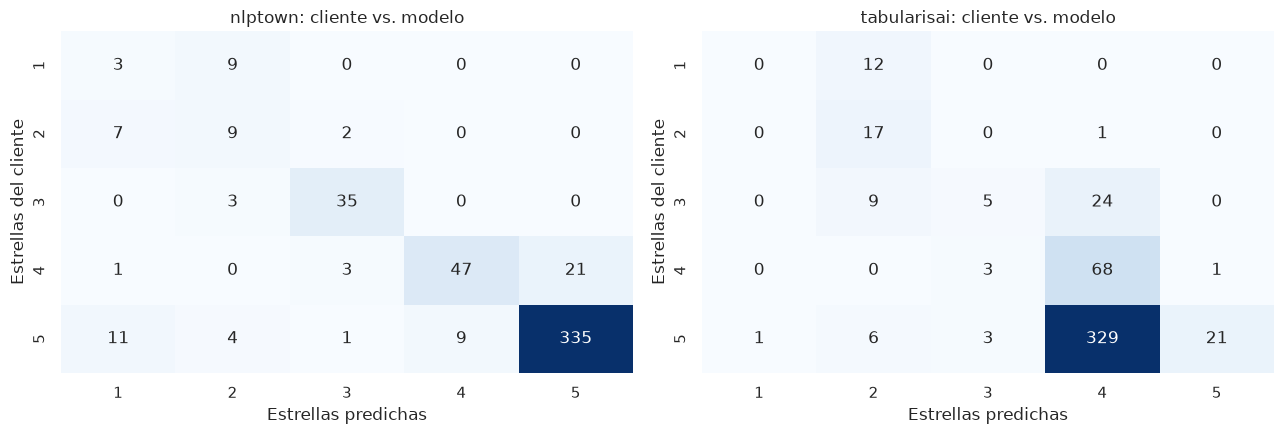

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in [(axes[0], "pred_stars", "nlptown"), (axes[1], "alt_stars", "tabularisai")]:
    cm = pd.crosstab(df["rating"], df[col]).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"{title}: cliente vs. modelo", xlabel="Estrellas predichas", ylabel="Estrellas del cliente")
plt.tight_layout()
plt.show()

In [41]:
both_fn = df["false_negative"] & df["alt_false_negative"]
print(f"Falsos negativos nlptown: {df['false_negative'].sum()} | tabularisai: {df['alt_false_negative'].sum()} | en ambos: {both_fn.sum()}")
print("\nFalsos negativos de tabularisai que contienen 'allergy':",
      df.loc[df["alt_false_negative"], "review_text"].str.contains("allergy").sum(), "/", df["alt_false_negative"].sum())
df.loc[df["alt_false_negative"], ["review_id", "rating", "alt_stars", "alt_score", "pred_stars", "review_text"]]

Falsos negativos nlptown: 16 | tabularisai: 7 | en ambos: 1

Falsos negativos de tabularisai que contienen 'allergy': 7 / 7


,review_id,rating,alt_stars,alt_score,pred_stars,review_text
138,139,5,2,0.4994,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. They went out of their way to accommodate my allergy. Five stars without hesitation.
219,220,5,2,0.4731,5,Visited Harbor House Café last weekend. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
230,231,5,2,0.4662,5,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. This is now my go-to spot.
253,254,5,2,0.6090,1,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
289,290,5,2,0.4001,5,Grabbed a quick coffee at Harbor House Café this morning. Best brunch i've had in months. They went out of their way to accommodate my allergy. Five stars without hesitation.
351,352,5,1,0.4740,5,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. Five stars without hesitation.
414,415,5,2,0.3796,5,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.


### Recomendación

| | nlptown | tabularisai |
|---|---|---|
| Falsos negativos | 16 | **7** ✅ |
| Coincidencia de banda | **95.0 %** ✅ | 90.6 % |
| Neutrales detectadas (de 38) | **35** ✅ | 5 |
| Estrella exacta | **85.8 %** ✅ | 22.2 % |

- **tabularisai reduce los falsos negativos de 16 a 7.** Ya no se confunde con *"bursting"*, pero **sigue fallando con *"allergy"***: sus 7 falsos negativos contienen esa palabra, así que el sesgo de dominio no desaparece.
- A cambio, **pierde casi toda la capacidad de detectar neutrales**: 24 de las 38 reseñas de 3★ las clasifica como positivas. Además casi nunca usa *Very Positive*, así que su escala no se corresponde con las estrellas (solo el 22 % de coincidencia exacta).
- Para el cliente, **las reseñas neutrales son tan importantes como las negativas**, porque señalan dónde mejorar. Un modelo que convierte "average service, nothing memorable" en positivo **infla** el resultado.

**Recomendación: mantener `nlptown`** para este cliente. Sus errores son pocos, predecibles y se detectan con la confianza (`needs_review`). Cambiar a tabularisai cambiaría 16 errores identificables por una distribución sesgada hacia lo positivo. Si se quiere ir más allá, la opción natural es **combinar ambos modelos**: cuando nlptown tiene baja confianza y tabularisai discrepa, se marca la reseña para revisión humana. Otra opción, a medio plazo, es **hacer fine-tuning con reseñas de servicios**.